# 01 · U1 MPC — 반복 최적화와 receding horizon

**한 줄 요약 (노션 U1):** 짧은 미래의 행동열을 반복 계산하고 첫 행동을 실행한 뒤, 갱신된 입력으로 다시 계획하는 제어 구조.

### 학습 목표
1. 가속도 입력 모델에서 행동열 → 미래 상태 예측(rollout)이 어떻게 되는지 직접 구현한다.
2. 한 번 푼 개루프 계획과, 매 스텝 다시 푸는 MPC(receding horizon)의 차이를 모델 오차가 있는 상황에서 비교한다.
3. warm start(직전 계획 shift)가 최적화 반복 수를 얼마나 줄이는지 측정한다.
4. 장애물이 경로를 막을 때 **직진 / 정지 / 우회** 후보의 비용이 horizon 길이에 따라 어떻게 바뀌는지 확인한다 → local minimum.
5. `hand_experiment.py`의 제어 루프에서 위 개념이 어디에 있는지 찾는다.

### 노션 정리와의 연결
| 노션 U1 기록 | 이 노트에서 확인할 것 |
|---|---|
| 매 loop `mpc.step` 호출과 지도 반영 | 6절: `hand_experiment.py` 루프 구조 |
| 직전 행동열 shift → warm start | 3절: shift warm start vs cold start 반복 수 |
| 최적화 변수 = 7관절 가속도 | 1절: 같은 구조를 2D 점질량으로 |
| horizon 30 step ≈ 0.75 s | 03 노트북에서 정정: 최종 실험은 base dt 1/60 → **0.675 s** |
| 직전 MPC 명령을 다음 MPC 상태로 사용 | 6절: 최종 replay는 `--state-input measured` (06 노트북에서 로그로 확인) |
| 목표에 도달하지 못할 수 있는 이유 | 5절: 후보별 비용 vs horizon |

여기서는 cuRobo 대신 **2D 점질량 + scipy L-BFGS-B(gradient 기반)** 로 MPC를 만든다. 샘플링 기반(MPPI)은 02 노트북에서 같은 장면으로 다시 푼다.

In [1]:
import time
import numpy as np
from scipy.optimize import minimize
from common import *
from toy import PointMass2D, Scene, draw_scene
plt = setup_plot()
check_paths()

REPO      OK  ~/franka-depth-mppi
CUROBO    OK  ~/curobo
TAPE      OK  ~/franka-depth-mppi/data/hand-tape-20261012-000004-472steps-registered
EVIDENCE  OK  ~/franka-depth-mppi/evidence


## 1. 가속도 입력 모델과 rollout

cuRobo MPPI 설정 `particle_mpc.yml`의 `control_space: 'ACCELERATION'`처럼, 최적화 변수는 가속도 열 $A = (a_0,\dots,a_{N-1})$이고 상태는 적분으로 얻는다.

$$
v_{k+1} = v_k + a_k\,\Delta t,\qquad p_{k+1} = p_k + v_k\,\Delta t + \tfrac12 a_k\,\Delta t^2
$$

이 식을 풀어 쓰면 미래 위치는 **가속도에 대해 선형**이다.

$$
P = p_0 + t\,v_0 + M_p A,\qquad M_p[k,j] = \Delta t^2\,(k-j+\tfrac12)\ (j\le k)
$$

`toy.PointMass2D`는 이 행렬 $M_p, M_v$를 미리 만들어 두고, 행동열 한 개(`[N,2]`)든 400개 묶음(`[400,N,2]`)이든 한 번에 rollout한다. cuRobo의 `act_seq[400,30,7] → 관절 상태` 변환(03 노트북)과 같은 역할이다. 차이는 cuRobo는 그 뒤에 FK로 충돌 구 위치까지 계산한다는 점이다.

In [2]:
model = PointMass2D(dt=0.05, horizon=30)
print('Mp shape', model.Mp.shape, '| 하삼각 행렬인가:', np.allclose(model.Mp, np.tril(model.Mp)))

# 행렬식 rollout이 한 스텝씩 적분한 것과 같은지 확인
rng = np.random.default_rng(0)
A = rng.normal(size=(30, 2))
P, V = model.rollout(np.zeros(2), np.array([0.2, 0.0]), A)
p, v = np.zeros(2), np.array([0.2, 0.0])
for k in range(30):
    p, v = model.step(p, v, A[k])
print('행렬 rollout 마지막 위치 :', P[-1].round(6))
print('스텝 적분 마지막 위치   :', p.round(6))

# 묶음 rollout: 후보 400개를 한 번에
P400, V400 = model.rollout(np.zeros(2), np.zeros(2), rng.normal(size=(400, 30, 2)))
print('batch rollout:', P400.shape)

Mp shape (30, 30) | 하삼각 행렬인가: True
행렬 rollout 마지막 위치 : [0.07538  0.197341]
스텝 적분 마지막 위치   : [0.07538  0.197341]
batch rollout: (400, 30, 2)


## 2. 비용 함수와 한 번의 개루프 최적화

비용은 cuRobo `arm_reacher`처럼 **여러 항의 합**이다 (`toy.Scene.step_costs`).

$$
J(A) = \sum_{k} \Big[w_g\|p_k-g\|^2 + w_a\|a_k\|^2 + w_o\,C_\eta(\text{gap}_k)\Big] + w_T\|p_N-g\|^2 + w_v\|v_N\|^2
$$

장애물 항 $C_\eta$는 cuRobo 충돌 커널과 같은 activation-distance 비용(`common.eta_cost`)이다. 간격이 η보다 크면 0, η 안에서는 2차, 겹치면 1차로 커진다(03 노트북에서 자세히).

위치가 가속도에 선형이라 gradient를 해석적으로 구할 수 있다: $\nabla_A J = M_p^\top \nabla_P J + M_v^\top \nabla_V J + 2w_a A$. 아래에서 수치 미분과 비교해 확인한 뒤 L-BFGS-B(가속도 한계 `±a_max` = cuRobo의 CLAMP 역할)로 푼다.

해석 gradient vs 수치 gradient 최대 오차: 1.69e-07
함수 호출 152회, horizon 끝 위치 [1.003 0.016], 최소 간격 0.095 m


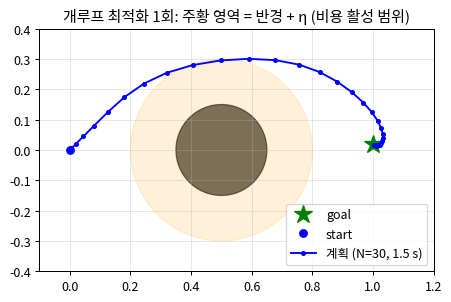

In [3]:
scene = Scene(goal=[1.0, 0.02], obstacles=[([0.5, 0.0], 0.15)])
p0, v0 = np.zeros(2), np.zeros(2)

# gradient 확인
A = rng.normal(size=(30, 2))
c, g = scene.cost_and_grad(model, p0, v0, A)
gn = np.zeros_like(A); e = 1e-6
for i in range(30):
    for d in range(2):
        B = A.copy(); B[i, d] += e
        gn[i, d] = (scene.cost_and_grad(model, p0, v0, B)[0] - c) / e
print('해석 gradient vs 수치 gradient 최대 오차: %.2e' % np.abs(gn - g).max())


def solve(model, scene, p, v, A_init, maxiter=200):
    # 가속도 열 하나를 최적화. 반환: (최적 A, 비용함수 호출 수)
    def f(x):
        c, g = scene.cost_and_grad(model, p, v, x.reshape(-1, 2))
        return c, g.ravel()
    r = minimize(f, A_init.ravel(), jac=True, method='L-BFGS-B',
                 bounds=[(-model.a_max, model.a_max)] * A_init.size, options={'maxiter': maxiter})
    return r.x.reshape(-1, 2), r.nfev


A_opt, nfev = solve(model, scene, p0, v0, np.zeros((30, 2)))
P_opt, _ = model.rollout(p0, v0, A_opt)
print('함수 호출 %d회, horizon 끝 위치 %s, 최소 간격 %.3f m' % (nfev, P_opt[-1].round(3), scene.gaps(P_opt).min()))

fig, ax = plt.subplots(figsize=(6, 3.5))
draw_scene(ax, scene, p0, lim=((-0.1, 1.2), (-0.4, 0.4)))
ax.plot(*P_opt.T, 'b.-', label='계획 (N=30, 1.5 s)')
ax.set_title('개루프 최적화 1회: 주황 영역 = 반경 + η (비용 활성 범위)')
ax.legend(loc='lower right'); plt.show()

## 3. Receding horizon과 warm start

MPC 루프는 아래를 반복한다. `hand_experiment.py`의 메인 루프도 같은 골격이다 (6절).

```text
for step:
    x = 현재 상태 측정
    A* = argmin_A J(A; x)        # warm start: 직전 A*를 한 칸 shift한 값에서 시작
    실행: a_0* 하나만 적용
    A_init ← [a_1*, a_2*, ..., a_{N-1}*, a_{N-1}*]   # shift
```

직전 계획은 이번 문제의 좋은 초기값이다. 상태가 한 스텝만큼만 바뀌었기 때문이다. 아래에서 shift warm start와 매번 0에서 시작(cold start)하는 경우의 함수 호출 수를 비교한다. cuRobo MPPI에서는 평균 행동열 `mean_action`을 shift하는 것이 같은 역할이다 (`control-settings.json`의 `shift_steps: 1`).

warm start: 평균 함수 호출 11.3회, 0.24s
cold start: 평균 함수 호출 31.1회, 0.58s
두 경우 실행 궤적 최대 차이: 0.0179 m


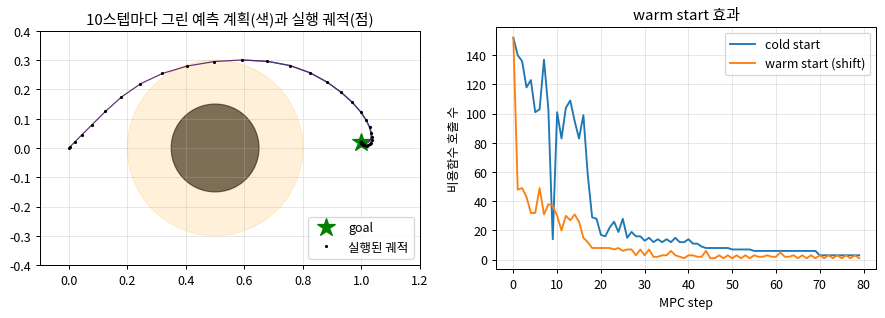

In [4]:
def run_mpc(scene, N=30, steps=80, warm=True, plant=None):
    # plant(p, v, a) -> (p, v): 실제 시스템. None이면 모델과 동일
    m = PointMass2D(dt=0.05, horizon=N)
    plant = plant or m.step
    p, v = np.zeros(2), np.zeros(2)
    A = np.zeros((N, 2))
    traj, nfevs, plans = [p], [], []
    for k in range(steps):
        A, nf = solve(m, scene, p, v, A if warm else np.zeros((N, 2)))
        nfevs.append(nf)
        if k % 10 == 0:
            plans.append(m.rollout(p, v, A)[0])
        p, v = plant(p, v, A[0])           # 첫 행동만 실행
        traj.append(p)
        if warm:
            A = np.vstack([A[1:], A[-1:]])  # shift
    return np.array(traj), np.array(nfevs), plans


t0 = time.time(); tr_w, nf_w, plans = run_mpc(scene, warm=True); tw = time.time() - t0
t0 = time.time(); tr_c, nf_c, _ = run_mpc(scene, warm=False); tc = time.time() - t0
print('warm start: 평균 함수 호출 %.1f회, %.2fs' % (nf_w.mean(), tw))
print('cold start: 평균 함수 호출 %.1f회, %.2fs' % (nf_c.mean(), tc))
print('두 경우 실행 궤적 최대 차이: %.4f m' % np.abs(tr_w - tr_c).max())

fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
draw_scene(axs[0], scene, lim=((-0.1, 1.2), (-0.4, 0.4)))
for i, P in enumerate(plans):
    axs[0].plot(*P.T, '-', color=plt.cm.viridis(i / len(plans)), lw=1, alpha=0.8)
axs[0].plot(*tr_w.T, 'k.', ms=3, label='실행된 궤적')
axs[0].set_title('10스텝마다 그린 예측 계획(색)과 실행 궤적(점)'); axs[0].legend(loc='lower right')
axs[1].plot(nf_c, label='cold start'); axs[1].plot(nf_w, label='warm start (shift)')
axs[1].set_xlabel('MPC step'); axs[1].set_ylabel('비용함수 호출 수'); axs[1].legend()
axs[1].set_title('warm start 효과')
plt.show()

**관찰 포인트**
- 예측 계획(색 선)은 매번 1.5 s 앞까지 그려지지만 실제로는 첫 점만 실행된다. 다음 스텝에서 계획은 다시 만들어진다.
- 모델이 정확하고 장면이 그대로면 warm/cold의 실행 궤적은 거의 같고, 계산량만 차이가 난다. MPPI처럼 반복 횟수가 고정(`n_iters: 5`)인 경우에는 warm start가 **같은 계산량에서 더 좋은 해**로 나타난다.

## 4. 왜 매번 다시 푸는가 — 모델 오차에 대한 피드백

실제 시스템이 모델과 다르면 개루프 계획은 점점 벗어난다. 여기서는 실제 시스템에 **명령의 70%만 반영되는 추종 오차와 마찰**을 넣는다. Isaac Sim에서 관절 PD 드라이브가 cuRobo의 기구학 예측을 완벽히 따라가지 못하는 상황을 단순화한 것이다.

개루프   최종 목표 오차 0.957 m, 최소 장애물 간격 -0.171 m
MPC   최종 목표 오차 0.000 m, 최소 장애물 간격 0.107 m


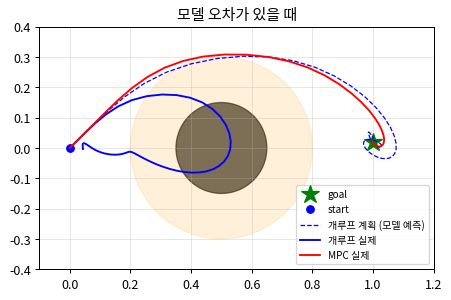

In [5]:
def lossy_plant(p, v, a, dt=0.05):
    a_real = 0.7 * a - 0.8 * v           # 추종 오차 + 마찰
    return p + v * dt + 0.5 * a_real * dt ** 2, v + a_real * dt

# (a) 개루프: 처음에 한 번 푼 80스텝 계획을 끝까지 실행
m80 = PointMass2D(dt=0.05, horizon=80)
A80, _ = solve(m80, scene, p0, v0, np.zeros((80, 2)))
p, v = p0.copy(), v0.copy(); open_loop = [p]
for a in A80:
    p, v = lossy_plant(p, v, a); open_loop.append(p)
open_loop = np.array(open_loop)
# (b) MPC: 같은 실제 시스템에서 매 스텝 재계획
tr_mpc, _, _ = run_mpc(scene, steps=80, plant=lossy_plant)

for name, tr in [('개루프', open_loop), ('MPC', tr_mpc)]:
    print('%-5s 최종 목표 오차 %.3f m, 최소 장애물 간격 %.3f m' % (name, np.linalg.norm(tr[-1] - scene.goal), scene.gaps(tr).min()))

fig, ax = plt.subplots(figsize=(6, 3.5))
draw_scene(ax, scene, p0, lim=((-0.1, 1.2), (-0.4, 0.4)))
ax.plot(*m80.rollout(p0, v0, A80)[0].T, 'b--', lw=1, label='개루프 계획 (모델 예측)')
ax.plot(*open_loop.T, 'b-', label='개루프 실제')
ax.plot(*tr_mpc.T, 'r-', label='MPC 실제')
ax.legend(loc='lower right', fontsize=8); ax.set_title('모델 오차가 있을 때'); plt.show()

개루프는 예측과 실제의 차이가 누적되어 목표에 못 가지만, MPC는 매 스텝 **현재 상태에서** 다시 풀기 때문에 오차를 보정한다. 이것이 MPC가 "짧은 계획 + 첫 행동만 실행"을 반복하는 이유다.

프로젝트에서 이 피드백 경로는 `--state-input` 옵션이 정한다 (6절).
- `command`: 직전 MPC 명령을 다음 입력 상태로 쓴다. 실제 추종 오차를 보지 않는다.
- `measured`: Isaac Sim에서 측정한 관절 위치·속도를 쓴다. 최종 replay(`scripts/replay.sh`)가 이 설정이다.

## 5. 장애물이 길을 막을 때 — 직진 / 정지 / 우회 후보

노션 U1의 "목표에 도달하지 못할 수 있는 이유"를 숫자로 확인한다. 목표 앞을 넓은 벽이 막고 있고, 위쪽 끝으로만 돌아갈 수 있다. 세 후보 경로를 직접 만들고, **horizon 길이 N만큼 잘라서** 같은 비용 함수로 평가한다.
- 직진: 목표를 향해 일정 속도로 직진. 벽을 관통한다.
- 정지: 제자리에 머문다.
- 우회: 벽 위쪽 끝을 돌아 목표로 간다.

N= 10 (0.50 s): 직진 189.1, 정지 16.9, 우회 17.2  -> 최저: 정지
N= 20 (1.00 s): 직진 321.6, 정지 22.5, 우회 26.2  -> 최저: 정지
N= 40 (2.00 s): 직진 320.4, 정지 33.8, 우회 25.1  -> 최저: 우회
N= 80 (4.00 s): 직진 320.4, 정지 56.2, 우회 22.1  -> 최저: 우회
N=120 (6.00 s): 직진 320.4, 정지 78.8, 우회 22.1  -> 최저: 우회


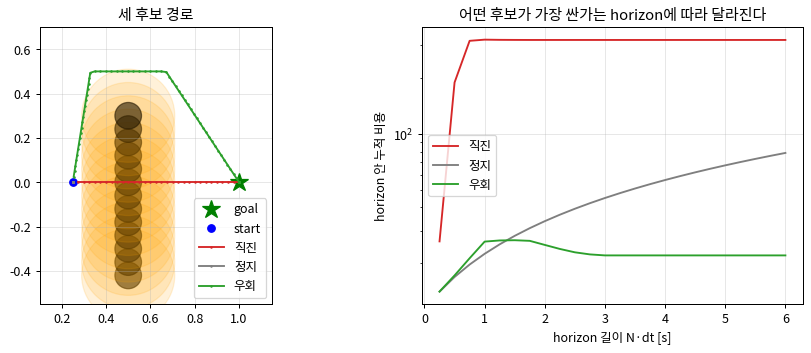

In [6]:
wall = [([0.5, y], 0.06) for y in np.arange(-0.42, 0.31, 0.06)]
wscene = Scene(goal=[1.0, 0.0], obstacles=wall)
start = np.array([0.25, 0.0]); dt = 0.05; speed = 0.5


def path_from_waypoints(wps, total_steps=120):
    # 웨이포인트를 일정 속도로 따라가는 위치 열 (목표 도착 후 정지)
    wps = np.asarray(wps, float)
    seg = np.linalg.norm(np.diff(wps, axis=0), axis=1)
    s_wp = np.concatenate([[0], np.cumsum(seg)])
    s = np.minimum(speed * dt * np.arange(1, total_steps + 1), s_wp[-1])
    return np.stack([np.interp(s, s_wp, wps[:, d]) for d in range(2)], axis=1)


paths = {
    '직진': path_from_waypoints([start, wscene.goal]),
    '정지': np.tile(start, (120, 1)),
    '우회': path_from_waypoints([start, [0.33, 0.5], [0.67, 0.5], wscene.goal]),
}


def cost_of_path(P, N):
    # 처음 N 스텝만 보고 비용 계산 (V, A는 차분으로 근사)
    P = P[:N]
    V = np.diff(np.vstack([start, P]), axis=0) / dt
    A = np.diff(np.vstack([np.zeros(2), V]), axis=0) / dt
    return wscene.step_costs(P, V, A).sum()


Ns = np.arange(5, 121, 5)
costs = {k: np.array([cost_of_path(P, N) for N in Ns]) for k, P in paths.items()}

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
draw_scene(axs[0], wscene, start, lim=((0.1, 1.15), (-0.55, 0.7)))
for (k, P), col in zip(paths.items(), ['tab:red', 'tab:gray', 'tab:green']):
    axs[0].plot(*P.T, '.-', ms=2, color=col, label=k)
axs[0].legend(); axs[0].set_title('세 후보 경로')
for k, col in zip(paths, ['tab:red', 'tab:gray', 'tab:green']):
    axs[1].plot(Ns * dt, costs[k], color=col, label=k)
axs[1].set_yscale('log'); axs[1].set_xlabel('horizon 길이 N·dt [s]'); axs[1].set_ylabel('horizon 안 누적 비용')
axs[1].legend(); axs[1].set_title('어떤 후보가 가장 싼가는 horizon에 따라 달라진다')
plt.show()

for N in [10, 20, 40, 80, 120]:
    i = list(Ns).index(N)
    best = min(costs, key=lambda k: costs[k][i])
    print('N=%3d (%.2f s): ' % (N, N * dt) + ', '.join('%s %.1f' % (k, costs[k][i]) for k in costs) + '  -> 최저: ' + best)

**해석**
- horizon이 짧으면 우회 경로는 처음에 목표에서 **멀어지는** 구간만 보인다. 그래서 목표 오차 비용이 늘고, 정지가 가장 싸다. 이것이 "장애물 앞 정지·머뭇거림" local minimum이다.
- horizon이 우회의 이득(목표 접근)이 드러날 만큼 길어지면 우회가 가장 싸진다.
- 직진은 충돌 비용 때문에 항상 비싸다. 하지만 soft cost이므로 다른 후보도 모두 비싸면 덜 나쁜 직진이 선택될 수 있다(02 노트북의 β 논의).

같은 벽에서 gradient 기반 MPC를 실제로 돌려 보면, horizon을 늘려도 0에서 시작한 국소 최적화는 우회 해로 건너가지 못한다. 후보 비용이 우회 쪽에서 더 낮아도 그 해까지 가는 경로가 막혀 있기 때문이다.

In [7]:
for N in [10, 40, 80]:
    tr, _, _ = run_mpc(wscene, N=N, steps=150)
    print('gradient MPC N=%2d: 최종 위치 %s, 목표 오차 %.3f m' % (N, tr[-1].round(3), np.linalg.norm(tr[-1] - wscene.goal)))

gradient MPC N=10: 최종 위치 [ 0.293 -0.028], 목표 오차 0.708 m
gradient MPC N=40: 최종 위치 [0.291 0.   ], 목표 오차 0.709 m
gradient MPC N=80: 최종 위치 [0.291 0.   ], 목표 오차 0.709 m


gradient 기반 국소 최적화는 horizon이 길어도 벽 앞에서 멈춘다. MPPI는 평균 주변에 넓게 샘플을 뿌려 다른 골짜기의 후보도 평가하므로 이 문제가 줄어들 수 있다. 02 노트북에서 같은 벽으로 비교한다.

정리하면 local minimum의 원인은 두 가지가 겹친다.
1. **horizon이 짧아** 우회의 이득이 비용에 드러나지 않는다 (위 그래프).
2. **최적화기가 국소적이라** 더 좋은 해가 있어도 찾아가지 못한다.

프로젝트에서 판단 지표를 "비충돌 여부"와 "목표 도달 여부"로 나눠 기록한 이유가 여기에 있다. 최종 실험은 실제 EE 도달(위치 ≤10 mm, 자세 ≤0.05 rad)을 따로 판정한다 (`goal_progress.py`).

## 6. 실제 코드 연결 — `hand_experiment.py` 메인 루프

아래 줄들이 위의 MPC 골격에 해당한다.

| 개념 | 위치 |
|---|---|
| 지도 갱신 (깊이 → nvblox) | `hand_experiment.py:243-246` |
| 현재 상태 측정 / 입력 선택 (`command` vs `measured`) | `:278-282` |
| 실제 EE 도달 판정 → 목표 전환 | `:287-296` |
| `mpc.step(current)` = 최적화 1회(MPPI 5 iteration) | `:298` |
| 첫 행동 꺼내기 `result.js_action` | `:301` |
| infeasible이면 측정 위치 유지(`hold-measured`) | `:302-313` |
| Isaac Sim 관절 PD 목표로 적용 | `:317` |

In [8]:
src = REPO / 'experiment' / 'hand_experiment.py'
show_code(src, 278, 282, width=170)
print('...')
show_code(src, 296, 302, width=170)
print('...')
show_code(src, 315, 317, width=170)

  278|  state=robot.get_joints_state();actual=JointState(position=ta.to_device(state.positions),velocity=ta.to_device(state.velocities)*0,acceleration=ta.to_device(state.velocit ...
  279|  measured=actual.clone();measured.velocity.copy_(ta.to_device(state.velocities)[[robot.get_dof_index(n) for n in mpc.joint_names]])
  280|  if args.state_input=='measured':measured=measured.unsqueeze(0)
  281|  if args.state_input=='measured':assert measured.position.shape==current_state.position.shape
  282|  current_state.copy_(measured if args.state_input=='measured' else (actual if command is None else command.get_ordered_joint_state(mpc.joint_names)))
...
  296|  if within and args.goal_mode=='reached' and (plan_len is None or len(progress.arrivals)<plan_len):pending_switch=True
  297|  if probe:probe.begin()
  298|  torch.cuda.synchronize();begin=time.perf_counter();result=mpc.step(current,max_attempts=2);torch.cuda.synchronize();solver_s=time.perf_counter()-begin
  299|  optimizer_start=mpc.so

**읽는 법**
- `:282` `current_state.copy_(measured if args.state_input=='measured' else (actual if command is None else command...))`: 입력 상태 선택. `command`면 직전 명령을 상태로 넣는다(노션 U1의 기록). 최종 replay는 `measured`다.
- `:298` `mpc.step(current, max_attempts=2)`: 내부에서 warm start shift, MPPI 5회 반복, BEST 후보 선택이 일어난다(02 노트북).
- `:317` 명령은 **관절 위치 목표**로 Isaac Sim PD 드라이브에 들어간다. `drive_velocity_target=zero`가 기본이다. 실제 관절은 PD 동역학으로 따라가므로 4절의 "모델 오차"가 생긴다.

cuRobo 안쪽에서는 측정 상태가 바로 optimizer로 들어가지 않고 **state filter**(위치·속도 계수 0.1, `particle_mpc.yml`의 `state_filter_cfg`)를 거친다. 그래서 측정 상태와 optimizer 시작 상태가 다르다. 06 노트북에서 로그로 크기를 확인한다.

## 정정 포인트

| 이전 이해 | 정정 |
|---|---|
| horizon = 30 × 0.02 = 0.6 s | 가변 dt. dt 0.02면 0.75 s, 최종 실험(base dt 1/60)은 **0.675 s** (03 노트북) |
| 최종 실험도 직전 MPC 명령을 입력 상태로 사용 | 최종 replay는 `--state-input measured`. 측정값이 cuRobo state filter를 거쳐 들어간다 |
| horizon만 길게 하면 local minimum이 풀린다 | horizon은 비용에 우회 이득을 드러내는 조건일 뿐이다. 국소 최적화기는 여전히 갇힐 수 있다 |

## 복습 질문

<details><summary>1. MPC가 계획 전체가 아니라 첫 행동만 실행하는 이유는?</summary>
모델 오차·외란·지도 변화 때문에 계획의 뒷부분은 시간이 지나면 틀려진다. 매 스텝 새 측정에서 다시 풀면 이 오차가 피드백으로 보정된다(4절).
</details>

<details><summary>2. warm start는 해를 바꾸는가, 계산량만 바꾸는가?</summary>
수렴할 때까지 푸는 최적화에서는 주로 계산량이 줄어든다(3절). MPPI처럼 반복 횟수가 고정이면 같은 계산량에서 도달하는 해가 달라진다. 비볼록 문제에서는 어느 골짜기에서 시작하느냐에 따라 다른 국소해로 갈 수도 있다.
</details>

<details><summary>3. 짧은 horizon에서 "정지"가 "우회"보다 싸지는 구조를 설명하면?</summary>
우회는 처음에 목표에서 멀어지는 구간이 있다. 그 구간만 보이는 짧은 horizon에서는 목표 오차 비용이 늘어난 것만 보이고, 목표 접근 이득은 horizon 밖에 있다. 정지는 충돌 비용 0, 목표 오차 일정이라 상대적으로 싸다.
</details>

<details><summary>4. `--state-input command`가 실제 관절 상태와 어긋날 수 있는 이유는?</summary>
명령은 PD 드라이브의 목표값일 뿐이고 실제 관절은 지연·오차를 두고 따라간다. command를 상태로 넣으면 이 추종 오차를 MPC가 보지 못한다(4절 개루프와 비슷한 문제).
</details>

**다음:** [02 · U2 MPPI](02_U2_mppi.ipynb) — 같은 점질량 장면을 샘플링 기반 MPPI로 풀고 cuRobo 파라미터(β, γ, step size, BEST)를 하나씩 바꿔 본다.